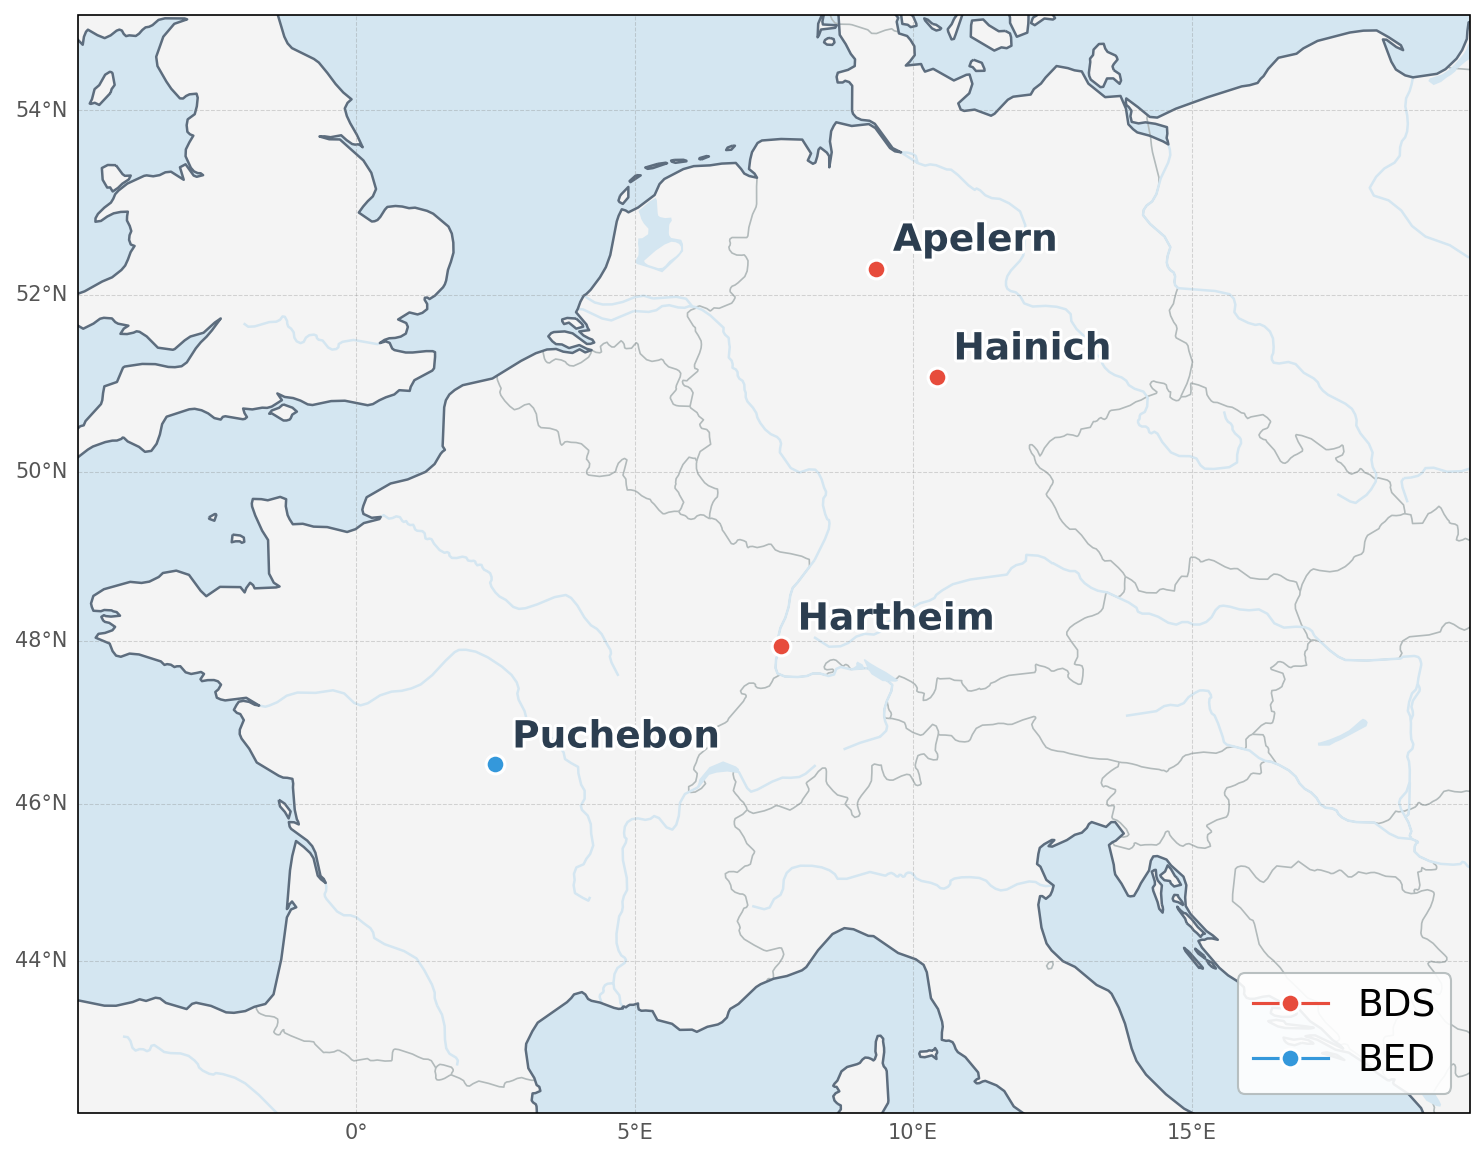

In [20]:
import urllib.request
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.patheffects as PathEffects

# Proxy setup to bypass firewalls for map downloads
proxy_support = urllib.request.ProxyHandler()
opener = urllib.request.build_opener(proxy_support)
urllib.request.install_opener(opener)

def create_beautiful_europe_map(show_labels=True):
    """
    Generates a high-quality, styled static map of Europe with custom colors and a legend.
    """
    
    # Expanded dictionary: (Latitude, Longitude, Category Group)
    locations = {
        "Hainich": (51.0813, 10.4243, "BDS"),
        "Apelern": (52.2891, 9.3373, "BDS"),
        "Hartheim": (47.9367, 7.6253, "BDS"),
        "Puchebon": (46.5000, 2.5000, "BED")
    }

    # Define the colors for each group
    category_colors = {
        "BDS": "#e74c3c", # Red
        "BED": "#3498db" ,  # Blue
        "BEM": "#0b4305"   # Blue
    }

    # Set up a high-resolution figure (slightly wider to accommodate the legend comfortably)
    fig = plt.figure(figsize=(10, 8), dpi=150)
    
    ax = plt.axes(projection=ccrs.Mercator())
    ax.set_extent([-5, 20, 42, 55], crs=ccrs.PlateCarree())

    # --- 1. Map Features ---
    ax.add_feature(cfeature.LAND.with_scale('50m'), facecolor='#f4f4f4', edgecolor='none')
    ax.add_feature(cfeature.OCEAN.with_scale('50m'), facecolor='#d4e6f1', edgecolor='none')
    ax.add_feature(cfeature.BORDERS.with_scale('50m'), linestyle='-', edgecolor='#b2babb', linewidth=0.8)
    ax.add_feature(cfeature.LAKES.with_scale('50m'), facecolor='#d4e6f1', edgecolor='none')
    ax.add_feature(cfeature.RIVERS.with_scale('50m'), edgecolor='#d4e6f1', linewidth=1.2)
    ax.coastlines(resolution='50m', color='#5d6d7e', linewidth=1.2)

    # --- 2. Gridlines ---
    gl = ax.gridlines(draw_labels=True, linewidth=0.5, color='gray', alpha=0.3, linestyle='--')
    gl.top_labels = False
    gl.right_labels = False
    gl.xlabel_style = {'size': 10, 'color': '#555555'}
    gl.ylabel_style = {'size': 10, 'color': '#555555'}

    # --- 3. Plotting Locations ---
    # We use a set to keep track of categories we've already plotted. 
    # This stops the legend from duplicating the "German Sites" label three times.
    plotted_categories = set()

    for name, data in locations.items():
        lat, lon, category = data
        
        # Add a label for the legend only if it's the first time we've seen this category
        plot_label = category if category not in plotted_categories else None
        plotted_categories.add(category)
        
        # Plot the marker, pulling the color from our category_colors dictionary
        ax.plot(lon, lat, marker='o', color=category_colors[category], markersize=9, 
                markeredgecolor='white', markeredgewidth=1.5,
                transform=ccrs.PlateCarree(), zorder=5, label=plot_label)
        
        if show_labels:
            txt = ax.text(lon + 0.3, lat + 0.2, name, 
                    transform=ccrs.PlateCarree(),
                    fontsize=18, fontweight='bold', color='#2c3e50',
                    zorder=6)
            txt.set_path_effects([PathEffects.withStroke(linewidth=3, foreground='white')])

    # --- 4. Add the Legend ---
    # We place it in the lower right so it doesn't overlap your central European points
    ax.legend(loc="lower right", title=None, title_fontsize="20", 
              fontsize="18", frameon=True, facecolor="white", framealpha=0.9, edgecolor="#b2babb")

    # --- 5. Final Layout ---
    #plt.title("Selected Locations in Europe", fontsize=18, fontweight='bold', pad=20, color='#333333')
    plt.tight_layout()
    plt.savefig("europe_site.png")
    #plt.show();


create_beautiful_europe_map(show_labels=True)

Map successfully saved as amazonia_site.png


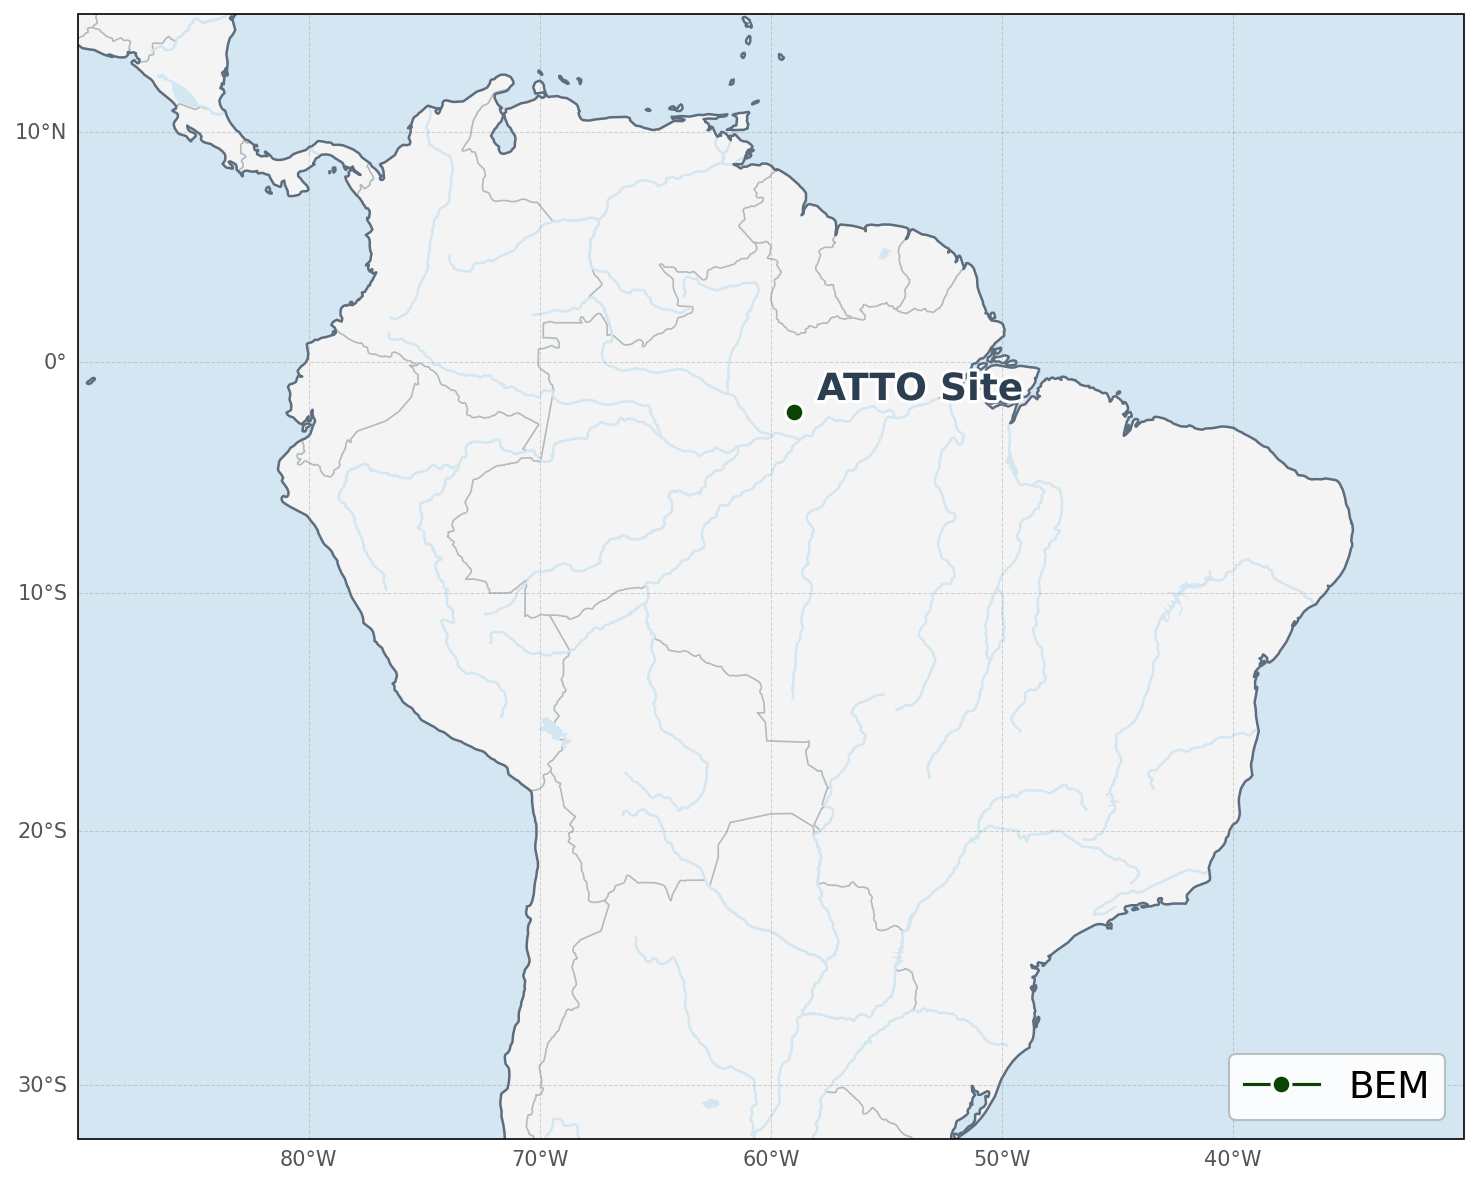

In [24]:
import urllib.request
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.patheffects as PathEffects

# Proxy setup to bypass firewalls for map downloads
proxy_support = urllib.request.ProxyHandler()
opener = urllib.request.build_opener(proxy_support)
urllib.request.install_opener(opener)

def create_beautiful_amazonia_map(show_labels=True):
    """
    Generates a high-quality, styled static map of Amazonia.
    """
    
    # Updated dictionary for Amazonia: (Latitude, Longitude, Category Group)
    locations = {
        "ATTO Site": (-2.1458, -59.0053, "BEM")
    }

    # Define the colors for each group
    category_colors = {
        "BDS": "#e74c3c",  # Red
        "BED": "#3498db",  # Blue
        "BEM": "#0b4305"   # Dark Green
    }

    # Set up a high-resolution figure
    fig = plt.figure(figsize=(10, 8), dpi=150)
    
    # Use Mercator projection
    ax = plt.axes(projection=ccrs.Mercator())

    # Focus the map extent on Amazonia/Northern South America
    # [min_lon, max_lon, min_lat, max_lat]
    ax.set_extent([-90, -30, -32, 15], crs=ccrs.PlateCarree())

    # --- 1. Map Features ---
    ax.add_feature(cfeature.LAND.with_scale('50m'), facecolor='#f4f4f4', edgecolor='none')
    ax.add_feature(cfeature.OCEAN.with_scale('50m'), facecolor='#d4e6f1', edgecolor='none')
    ax.add_feature(cfeature.BORDERS.with_scale('50m'), linestyle='-', edgecolor='#b2babb', linewidth=0.8)
    ax.add_feature(cfeature.LAKES.with_scale('50m'), facecolor='#d4e6f1', edgecolor='none')
    ax.add_feature(cfeature.RIVERS.with_scale('50m'), edgecolor='#d4e6f1', linewidth=1.2)
    ax.coastlines(resolution='50m', color='#5d6d7e', linewidth=1.2)

    # --- 2. Gridlines ---
    gl = ax.gridlines(draw_labels=True, linewidth=0.5, color='gray', alpha=0.3, linestyle='--')
    gl.top_labels = False
    gl.right_labels = False
    gl.xlabel_style = {'size': 10, 'color': '#555555'}
    gl.ylabel_style = {'size': 10, 'color': '#555555'}

    # --- 3. Plotting Locations ---
    plotted_categories = set()

    for name, data in locations.items():
        lat, lon, category = data
        
        # Add a label for the legend only if it's the first time we've seen this category
        plot_label = category if category not in plotted_categories else None
        plotted_categories.add(category)
        
        # Plot the marker
        ax.plot(lon, lat, marker='o', color=category_colors[category], markersize=9, 
                markeredgecolor='white', markeredgewidth=1.5,
                transform=ccrs.PlateCarree(), zorder=5, label=plot_label)
        
        if show_labels:
            # Slightly larger offset for text due to the larger map scale
            txt = ax.text(lon + 1.0, lat + 0.5, name, 
                    transform=ccrs.PlateCarree(),
                    fontsize=18, fontweight='bold', color='#2c3e50',
                    zorder=6)
            
            # Text Path Effects
            txt.set_path_effects([PathEffects.withStroke(linewidth=3, foreground='white')])

    # --- 4. Add the Legend ---
    ax.legend(loc="lower right", title=None, title_fontsize="20", 
              fontsize="18", frameon=True, facecolor="white", framealpha=0.9, edgecolor="#b2babb")

    # --- 5. Final Layout ---
    plt.tight_layout()
    plt.savefig("amazonia_site.png")
    print("Map successfully saved as amazonia_site.png")

create_beautiful_amazonia_map(show_labels=True)